In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [3]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/customer_segmentation_20000.csv")

In [4]:
df.head()

,CustomerID,Age,AnnualIncome,SpendingScore,PurchaseFrequency,AverageOrderValue,WebsiteVisitsPerMonth
0,100001,18,94.32,93.7,23,1811.95,13
1,100002,22,31.11,24.6,1,383.30,5
2,100003,39,42.37,74.7,12,524.51,15
3,100004,35,76.45,37.1,4,1091.86,7
4,100005,18,26.83,25.3,1,358.95,3


In [5]:
df.shape

(20000, 7)

In [6]:
df.columns

Index(['CustomerID', 'Age', 'AnnualIncome', 'SpendingScore',
       'PurchaseFrequency', 'AverageOrderValue', 'WebsiteVisitsPerMonth'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   CustomerID             20000 non-null  int64  
 1   Age                    20000 non-null  int64  
 2   AnnualIncome           20000 non-null  float64
 3   SpendingScore          20000 non-null  float64
 4   PurchaseFrequency      20000 non-null  int64  
 5   AverageOrderValue      20000 non-null  float64
 6   WebsiteVisitsPerMonth  20000 non-null  int64  
dtypes: float64(3), int64(4)
memory usage: 1.1 MB


In [29]:
df.isnull().sum()

CustomerID               0
Age                      0
AnnualIncome             0
SpendingScore            0
PurchaseFrequency        0
AverageOrderValue        0
WebsiteVisitsPerMonth    0
Cluster                  0
dtype: int64

In [7]:
df.describe()

,CustomerID,Age,AnnualIncome,SpendingScore,PurchaseFrequency,AverageOrderValue,WebsiteVisitsPerMonth
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,110000.500000,35.462900,60.751151,58.440735,10.037550,977.733892,7.880000
std,5773.647028,11.692102,24.938700,24.402748,6.980844,541.041787,5.781208
min,100001.000000,18.000000,10.000000,1.000000,0.000000,118.830000,0.000000
25%,105000.750000,26.000000,39.520000,38.600000,4.000000,530.562500,3.000000
50%,110000.500000,34.000000,62.100000,55.500000,8.000000,887.795000,6.000000
75%,115000.250000,44.000000,81.520000,80.800000,16.000000,1311.315000,13.000000
max,120000.000000,75.000000,122.770000,100.000000,30.000000,2888.190000,27.000000


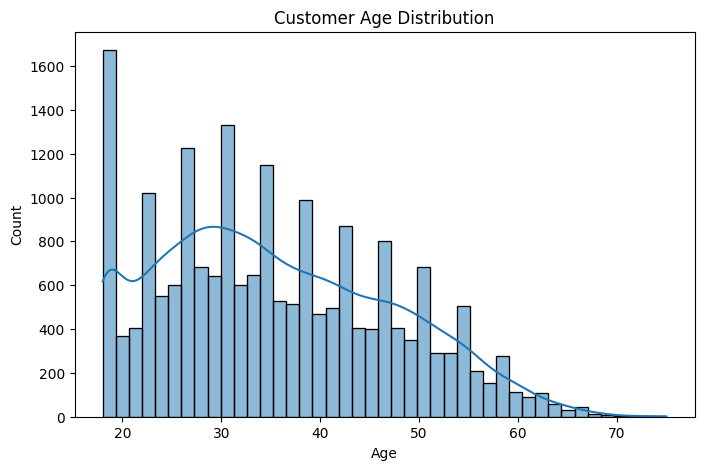

In [9]:
plt.figure(figsize=(8,5))
sns.histplot(df["Age"], kde=True)
plt.title("Customer Age Distribution")
plt.show()

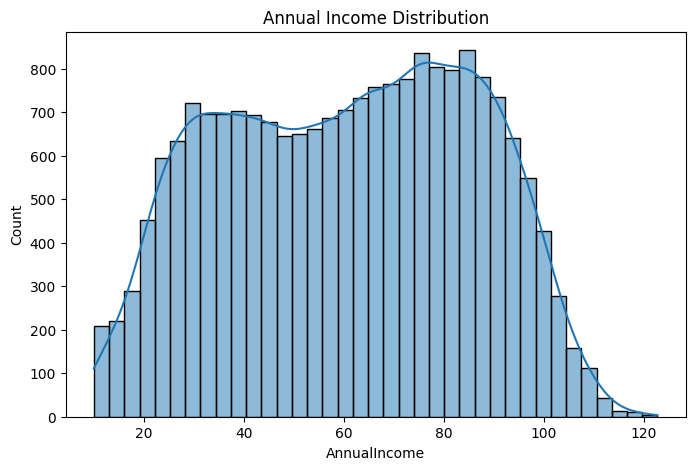

In [10]:
plt.figure(figsize=(8,5))
sns.histplot(df["AnnualIncome"], kde=True)
plt.title("Annual Income Distribution")
plt.show()

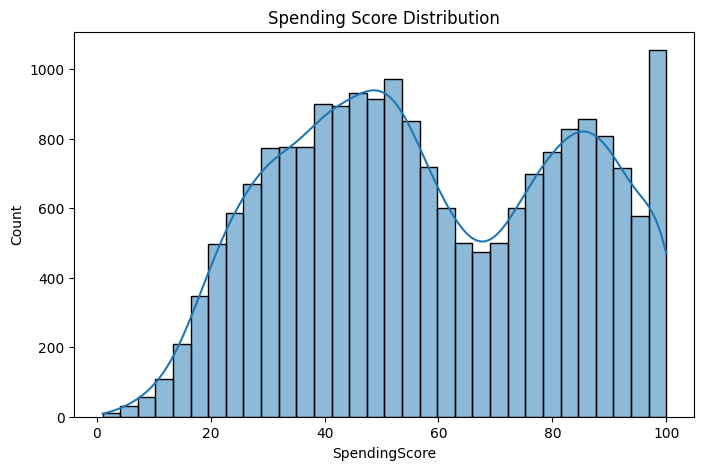

In [11]:
plt.figure(figsize=(8,5))
sns.histplot(df["SpendingScore"], kde=True)
plt.title("Spending Score Distribution")
plt.show()

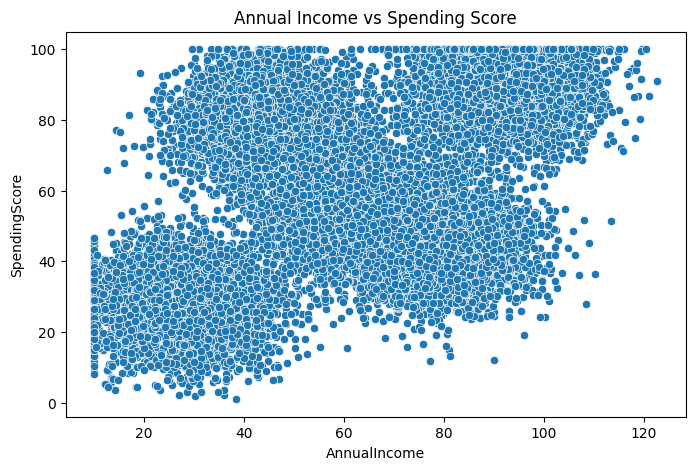

In [12]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x="AnnualIncome",
    y="SpendingScore"
)
plt.title("Annual Income vs Spending Score")
plt.show()

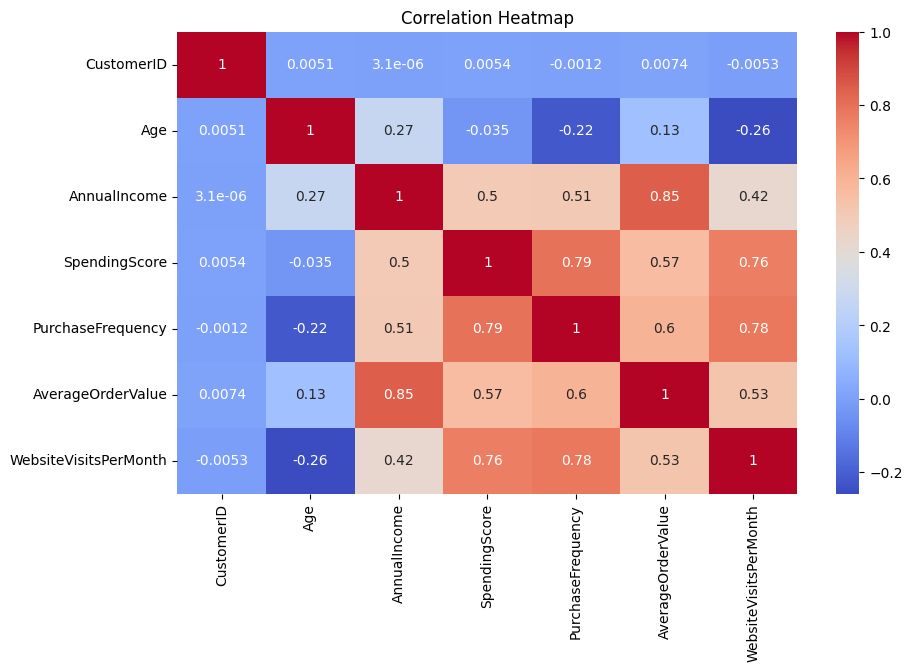

In [13]:
plt.figure(figsize=(10,6))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

In [15]:
X = df.drop("CustomerID", axis=1)

In [17]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled Data Shape:", X_scaled.shape)

Scaled Data Shape: (20000, 6)


In [18]:
wcss = []
for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10)

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

print(wcss)

[120000.00000000001, 69206.52639242724, 43457.778707802485, 26027.31277907361, 22215.269746556005, 21299.227924323684, 20593.207448942874, 19677.50876199579, 18927.182628220347, 18177.551551665587]


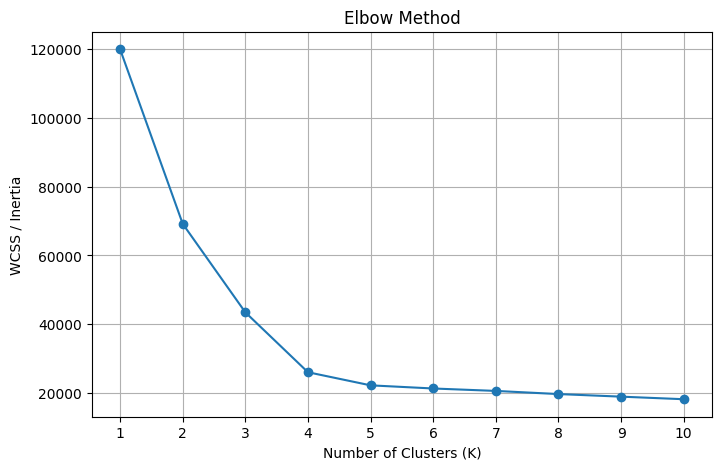

In [19]:
plt.figure(figsize=(8,5))
plt.plot(
    range(1, 11),
    wcss,
    marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid()
plt.show()

In [20]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

df["Cluster"] = clusters

df.head()

,CustomerID,Age,AnnualIncome,SpendingScore,PurchaseFrequency,AverageOrderValue,WebsiteVisitsPerMonth,Cluster
0,100001,18,94.32,93.7,23,1811.95,13,1
1,100002,22,31.11,24.6,1,383.30,5,0
2,100003,39,42.37,74.7,12,524.51,15,4
3,100004,35,76.45,37.1,4,1091.86,7,3
4,100005,18,26.83,25.3,1,358.95,3,0


In [21]:
print(df["Cluster"].value_counts().sort_index())

Cluster
0    4397
1    3979
2    3979
3    4050
4    3595
Name: count, dtype: int64


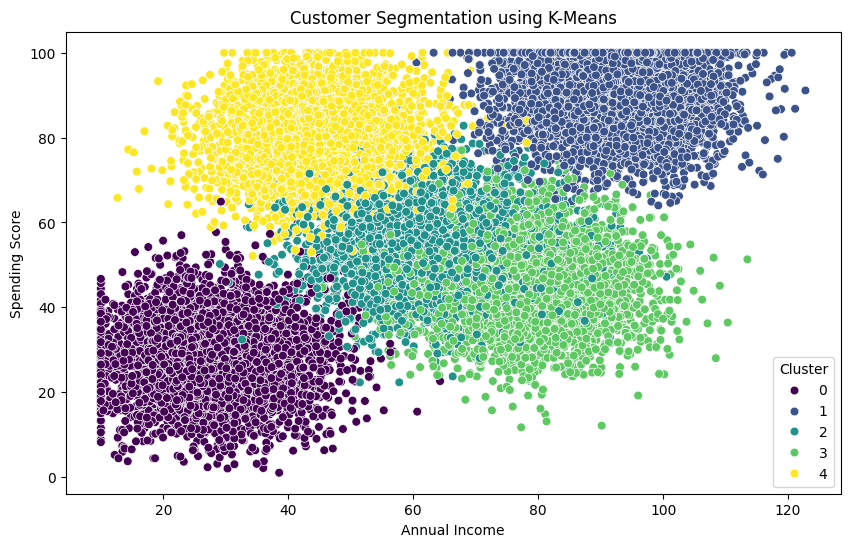

In [22]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df,
    x="AnnualIncome",
    y="SpendingScore",
    hue="Cluster",
    palette="viridis",
    s=40
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.show()

In [23]:
score = silhouette_score(X_scaled, clusters)
print("Silhouette Score:", score)

Silhouette Score: 0.43458450572925583


In [24]:
cluster_analysis = df.groupby("Cluster").agg({
    "Age": "mean",
    "AnnualIncome": "mean",
    "SpendingScore": "mean",
    "PurchaseFrequency": "mean",
    "AverageOrderValue": "mean",
    "WebsiteVisitsPerMonth": "mean",
    "CustomerID": "count"}).round(2)

cluster_analysis.rename(
    columns={"CustomerID": "CustomerCount"},
    inplace=True)
cluster_analysis

,Age,AnnualIncome,SpendingScore,PurchaseFrequency,AverageOrderValue,WebsiteVisitsPerMonth,CustomerCount
Cluster,,,,,,,
0,24.58,27.99,28.01,3.22,351.84,3.26,4397
1,29.26,92.20,89.55,19.99,1807.99,15.96,3979
2,52.17,62.82,54.65,5.09,918.20,4.12,3979
3,40.71,77.58,45.56,8.05,1190.28,4.98,4050
4,31.23,44.77,79.93,15.07,650.76,12.02,3595


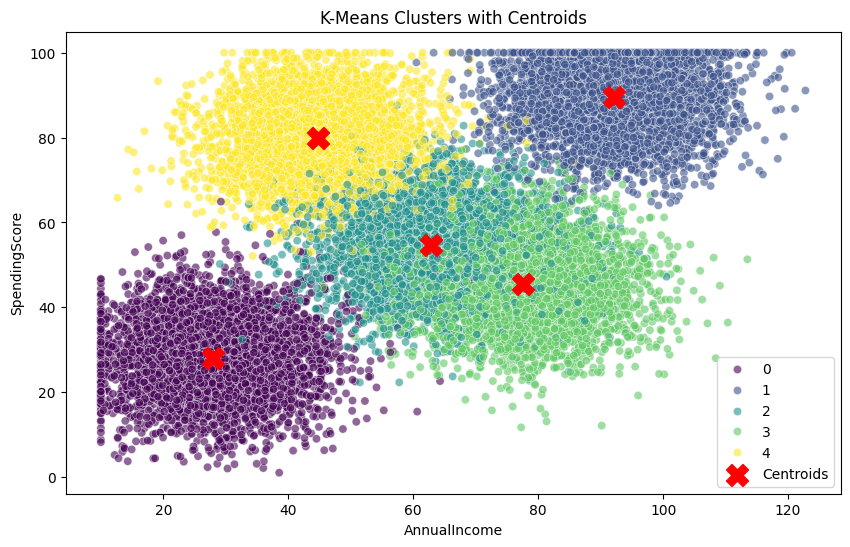

In [25]:
centers = scaler.inverse_transform(kmeans.cluster_centers_)
centers_df = pd.DataFrame(
    centers,
    columns=X.columns)

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df,
    x="AnnualIncome",
    y="SpendingScore",
    hue="Cluster",
    palette="viridis",
    alpha=0.6)

plt.scatter(
    centers_df["AnnualIncome"],
    centers_df["SpendingScore"],
    marker="X",
    s=250,
    color="red",
    label="Centroids")
plt.title("K-Means Clusters with Centroids")
plt.legend()
plt.show()

In [26]:
new_customer = pd.DataFrame([{
    "Age": 30,
    "AnnualIncome": 75,
    "SpendingScore": 85,
    "PurchaseFrequency": 15,
    "AverageOrderValue": 1200,
    "WebsiteVisitsPerMonth": 10}])

new_customer_scaled = scaler.transform(new_customer)

predicted_cluster = kmeans.predict(new_customer_scaled)

print("Predicted Customer Cluster:", predicted_cluster[0])

Predicted Customer Cluster: 4


In [27]:
joblib.dump(kmeans, "customer_segmentation_model.pkl")
joblib.dump(scaler, "customer_scaler.pkl")
print("Model and Scaler Saved Successfully!")

Model and Scaler Saved Successfully!


In [28]:
loaded_model = joblib.load("customer_segmentation_model.pkl")
loaded_scaler = joblib.load("customer_scaler.pkl")
new_scaled = loaded_scaler.transform(new_customer)
result = loaded_model.predict(new_scaled)
print("Customer Cluster:", result[0])

Customer Cluster: 4
